In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv("12-health_risk_classification.csv")

In [3]:
df

,bmi_score,blood_pressure_variation,activity_level_index,high_risk_flag
0,0.564223,0.652825,1.262925,1
1,-1.692569,2.981229,-0.180331,1
2,0.770383,0.400475,1.365806,1
3,2.135007,0.150832,3.084596,0
4,0.360342,1.026132,1.251574,1
...,...,...,...,...
995,0.640158,-1.962795,-0.541917,0
996,-2.784745,2.717867,-1.894291,1
997,0.238598,0.840739,0.946540,1
998,-1.044982,-0.055455,-1.496340,1


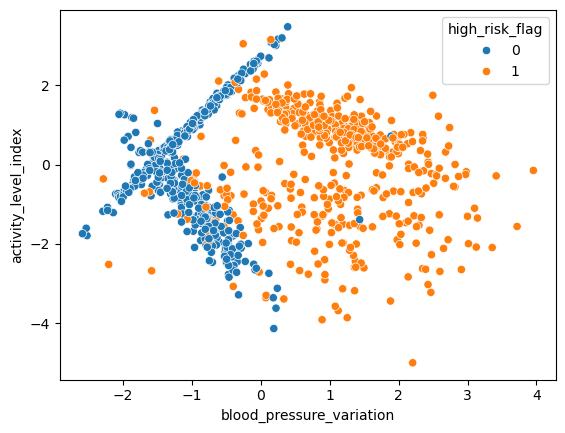

In [4]:
sns.scatterplot(data=df, x="blood_pressure_variation", y="activity_level_index", hue="high_risk_flag")
plt.show()

In [5]:
df["high_risk_flag"].value_counts()

high_risk_flag
0    502
1    498
Name: count, dtype: int64

In [6]:
X = df.drop("high_risk_flag", axis=1)
y = df["high_risk_flag"]

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=15)

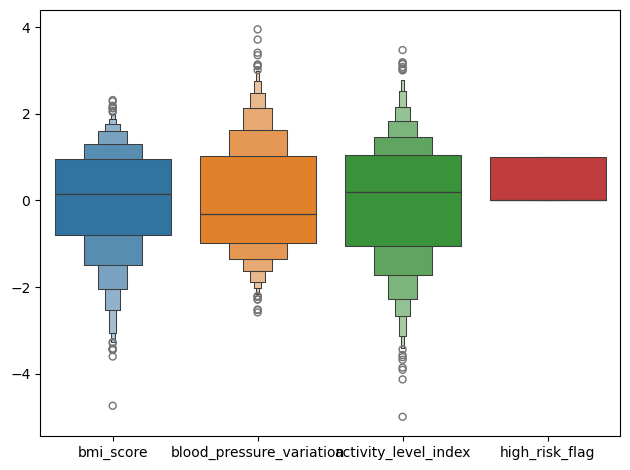

In [11]:
sns.boxenplot(data=df)
plt.tight_layout()
plt.show()

In [12]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [15]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
from sklearn.neighbors import KNeighborsClassifier

In [17]:
classifier = KNeighborsClassifier(n_neighbors=6, algorithm="auto", weights="uniform")

In [18]:
classifier.fit(X_train_scaled, y_train)

KNeighborsClassifier(n_neighbors=6)

In [19]:
y_pred = classifier.predict(X_test_scaled)

In [20]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [25]:

print("accuracy score:", accuracy_score(y_test, y_pred))
print("confusion matrix: \n", confusion_matrix(y_test, y_pred))
print("classification report: ", classification_report(y_test, y_pred))

accuracy score: 0.9566666666666667
confusion matrix: 
 [[154   4]
 [  9 133]]
classification report:                precision    recall  f1-score   support

           0       0.94      0.97      0.96       158
           1       0.97      0.94      0.95       142

    accuracy                           0.96       300
   macro avg       0.96      0.96      0.96       300
weighted avg       0.96      0.96      0.96       300



In [26]:
classifier = KNeighborsClassifier(n_neighbors=6, algorithm="kd_tree", weights="uniform")
classifier.fit(X_train_scaled, y_train)
y_pred = classifier.predict(X_test_scaled)
print("accuracy score:", accuracy_score(y_test, y_pred))
print("confusion matrix: \n", confusion_matrix(y_test, y_pred))
print("classification report: ", classification_report(y_test, y_pred))

accuracy score: 0.9566666666666667
confusion matrix: 
 [[154   4]
 [  9 133]]
classification report:                precision    recall  f1-score   support

           0       0.94      0.97      0.96       158
           1       0.97      0.94      0.95       142

    accuracy                           0.96       300
   macro avg       0.96      0.96      0.96       300
weighted avg       0.96      0.96      0.96       300



In [27]:
classifier = KNeighborsClassifier(n_neighbors=6, algorithm="ball_tree", weights="uniform")
classifier.fit(X_train_scaled, y_train)
y_pred = classifier.predict(X_test_scaled)
print("accuracy score:", accuracy_score(y_test, y_pred))
print("confusion matrix: \n", confusion_matrix(y_test, y_pred))
print("classification report: ", classification_report(y_test, y_pred))

accuracy score: 0.9566666666666667
confusion matrix: 
 [[154   4]
 [  9 133]]
classification report:                precision    recall  f1-score   support

           0       0.94      0.97      0.96       158
           1       0.97      0.94      0.95       142

    accuracy                           0.96       300
   macro avg       0.96      0.96      0.96       300
weighted avg       0.96      0.96      0.96       300



In [49]:
classifier = KNeighborsClassifier(n_neighbors=500, algorithm="ball_tree", weights="uniform")
classifier.fit(X_train_scaled, y_train)
y_pred = classifier.predict(X_test_scaled)
print("accuracy score:", accuracy_score(y_test, y_pred))
print("confusion matrix: \n", confusion_matrix(y_test, y_pred))
print("classification report: ", classification_report(y_test, y_pred))

accuracy score: 0.8433333333333334
confusion matrix: 
 [[142  16]
 [ 31 111]]
classification report:                precision    recall  f1-score   support

           0       0.82      0.90      0.86       158
           1       0.87      0.78      0.83       142

    accuracy                           0.84       300
   macro avg       0.85      0.84      0.84       300
weighted avg       0.85      0.84      0.84       300



In [50]:
# Regression with KNN

In [51]:
df_reg = pd.read_csv("12-house_energy_regression.csv")

In [52]:
df_reg

,avg_indoor_temp_change,outdoor_humidity_level,daily_energy_consumption_kwh
0,-0.167118,0.146714,-14.996950
1,-0.020902,0.117327,-12.678089
2,0.150419,0.364961,17.775455
3,0.555604,0.089581,6.661465
4,0.058209,-1.142970,-14.195530
...,...,...,...
995,-0.753965,-0.280675,-33.182365
996,-2.172670,0.847422,-71.059718
997,0.302635,-0.754276,3.260515
998,0.381935,0.430042,42.654703


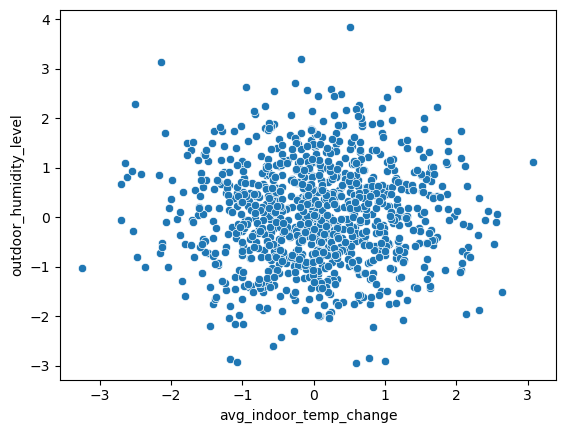

In [53]:
sns.scatterplot(data=df_reg, x="avg_indoor_temp_change", y="outdoor_humidity_level")
plt.show()

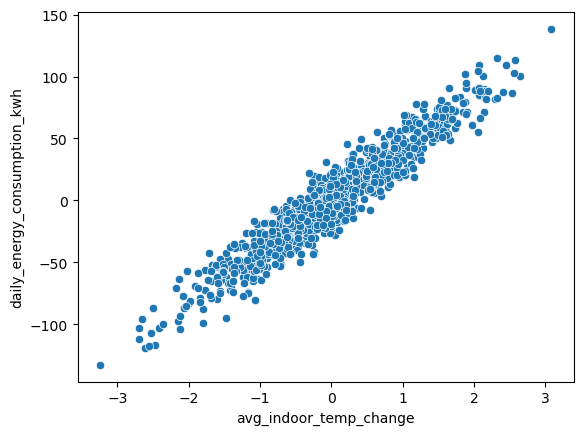

In [55]:
sns.scatterplot(data=df_reg, x="avg_indoor_temp_change", y="daily_energy_consumption_kwh")
plt.show()

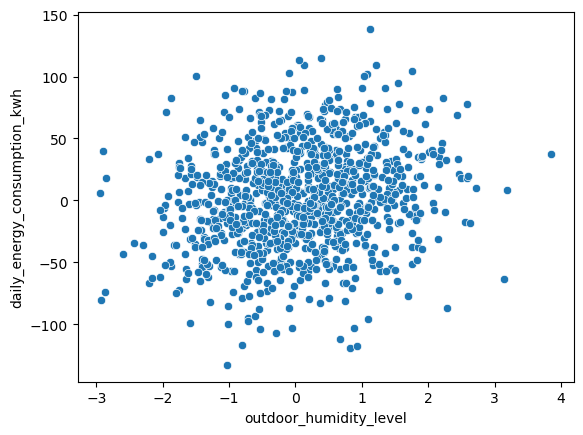

In [56]:
sns.scatterplot(data=df_reg, x="outdoor_humidity_level", y="daily_energy_consumption_kwh")
plt.show()

In [57]:
df_reg.corr()

,avg_indoor_temp_change,outdoor_humidity_level,daily_energy_consumption_kwh
avg_indoor_temp_change,1.000000,0.002584,0.956682
outdoor_humidity_level,0.002584,1.000000,0.169557
daily_energy_consumption_kwh,0.956682,0.169557,1.000000


In [58]:
X = df_reg.drop("daily_energy_consumption_kwh", axis=1)
y = df_reg["daily_energy_consumption_kwh"]

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=15)

In [60]:
from sklearn.neighbors import KNeighborsRegressor

In [61]:
regressor = KNeighborsRegressor(n_neighbors=5)

In [62]:
regressor.fit(X_train, y_train)

KNeighborsRegressor()

In [63]:
y_pred = regressor.predict(X_test)

In [64]:
y_pred

array([   2.4108035 ,  -48.07959714,   60.32778089,   19.79474464,
         54.96059863,   -0.30888346,  -14.37303606,   46.26743859,
        -32.90714435,  -20.17192347,  -30.04609632,   -1.24406674,
         76.1702516 , -101.27910786,  -50.58694109,  -15.14309911,
        -51.3515318 ,   32.01117519,   27.75527567,   85.06363471,
        -16.57082314,  -41.16251875,  -18.89695663,    0.28523963,
         18.30471593,  -34.00189977,    2.01183602,   -5.36316899,
         14.6491204 ,   20.45922431,  -16.69086542,  -12.52286481,
          3.73896358,  -25.08049953,   72.17914358,   71.74983396,
         -5.72228681,  -21.98545833,   24.70053692,  -33.15812743,
          4.71633351,   47.32532583,   23.8452807 ,  -44.49560707,
        -24.09946815,  -18.76261749,   61.77088114,   67.73972067,
        -60.95761814,   -2.28032856,  -50.84446013,   37.95277128,
         42.25862355,   89.46217092,  -10.14960008,   -4.22781986,
         64.69518467,   -5.0034235 ,   38.01473185,  -21.60054

In [65]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [66]:
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE: ", mean_squared_error(y_test, y_pred))
print("R2 Score: ", r2_score(y_test, y_pred))

MAE: 9.329789699164268
MSE:  137.54938006164943
R2 Score:  0.917173862980986


In [80]:
regressor = KNeighborsRegressor(n_neighbors=11)
regressor.fit(X_train, y_train)
y_pred = regressor.predict(X_test)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE: ", mean_squared_error(y_test, y_pred))
print("RMSE: ", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score: ", r2_score(y_test, y_pred))

MAE: 9.225736504600144
MSE:  134.79705715092217
RMSE:  11.61021348429572
R2 Score:  0.9188311897855291


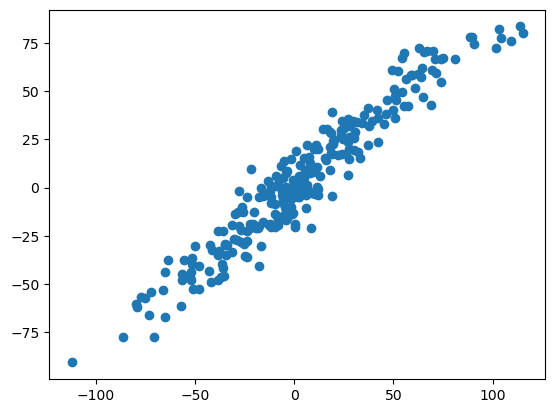

In [81]:
plt.scatter(y_test, y_pred)
plt.show()